In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.integrate import ode, odeint, solve_ivp
from scipy import constants as const
from scipy.interpolate import interp1d
from matplotlib.animation import FuncAnimation
from fractions import Fraction
import seaborn as sns

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 10})

In [2]:
def euler(f, t, y0, *args, **kwargs):
    """
    Eulerjeva metoda za reševanje sistema diferencialnih enačb: y' = f(t, y)
    
    :param f:  funkcija, ki vrne prvi odvod - f(t, y)
    :param t:  časovni vektor kjer računamo rešitev
    :param y0: začetna vrednosti
    :param args: dodatni argumenti funkcije f (brezimenski)
    :param kwargs: dodatni argumenti funkcije f (poimenovani)
    :return y: vrne np.array ``y`` vrednosti funkcije.
    """
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0        
    h = t[1]-t[0]
    for i in range(len(t)-1):
        y[i+1] = y[i] + f(t[i], y[i], *args, **kwargs) * h
    return y.T
def runge_kutta_4(f, t, y0, *args, **kwargs):
    """
    Metoda Runge-Kutta 4. reda za reševanje diferencialne enačbe: y' = f(t, y)
    
    :param f: funkcija, ki jo kličemo s parametroma t in y in vrne 
              vrednost prvega odvoda
    :param t: ekvidistanten časovni vektor oz. neodvisna spremenljivka
    :param y0: začetna vrednost
    :param args: dodatni argumenti funkcije f (brezimenski)
    :param kwargs: dodatni argumenti funkcije f (poimenovani)
    :return y: funkcijske vrednosti.
    """
    def RK4(f, t, y, *args, **kwargs):
        k0 = h*f(t, y, *args, **kwargs)
        k1 = h*f(t + h/2.0, y + k0/2.0, *args, **kwargs)
        k2 = h*f(t + h/2.0, y + k1/2.0, *args, **kwargs)
        k3 = h*f(t + h, y + k2, *args, **kwargs)
        return (k0 + 2.0*k1 + 2.0*k2 + k3)/6.0
    
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0
    h = t[1]-t[0]

    for i, ti in enumerate(t[1:]):
        y[i+1] = y[i] + RK4(f, ti, y[i], *args, **kwargs)
        
    return y.T
def verlet(f,t,y0,*args):
    '''Verlet algorithm with velocity. only for 2D problems of one planet!'''
    y = np.zeros(shape=(len(t),len(y0)))
    y[0] = y0
    h = t[1]-t[0] #const dt!

    a0 = f(t[0],y0,*args)[2:]#pospeški
    y[1,:2] = y0[:2] + y0[2:]*h + 0.5*a0*h*h

    # yi = np.array([y[1,0], y[1,1],0,0])
    # y[1,2:] = y0[2:] + 1/2*h*(a0+f(t[1],yi,*args)[2:])

    for i in range(1,len(t)-1):
        ai = f(t[i],y[i],*args)[2:]#pospeški
        x = 2*y[i,:2] - y[i-1,:2] + ai*h**2 #lega
        y[i+1,:2] = x
        # yi = np.array([x[0], x[1],0,0])
        # v = y[i,2:] + 1/2*h*(ai+f(t[i+1],yi,*args)[2:])#hitrost
        # y[i+1,2:] = v
    y[1:-1, 2:] = (y[2:,:2] - y[:-2,:2]) / (2*h) #post
    return y.T

In [3]:
# Function to initialize the plot
def init():
    for scatter in scatters:
        scatter.set_data([], [])
    return scatters
# Function to update the plot for each frame
def update(frame):
    for i, scatter in enumerate(scatters):
        if i < 2:  # Plot 'sonce 1' and 'sonce 2' as points
            x = [data[i, 0, frame]]
            y = [data[i, 1, frame]]
            scatter.set_data(x, y)
        else:  # Plot 'planet' as a line
            x = data[i, 0, :frame+1]
            y = data[i, 1, :frame+1]
            scatter.set_data(x, y)
    return scatters

# kepler

In [4]:
def kepler(t,y,*args):
    '''prvi odvod'''
    x1 = - y[0] /(y[0]**2 + y[1]**2)**(3/2)
    x2 = - y[1] /(y[0]**2 + y[1]**2)**(3/2)
    return np.array([y[2], y[3] ,x1, x2])
def kepler1(t,y,*args):
    '''prave enote!'''
    M,m=args
    G = const.G
    # dx/dt = v_x !!!
    # x1 = G*M*m*y[0] / (y[0]**2 + y[1]**2)**(3/2) - m*y[0]
    # x2 = G*M*m*y[0] / (y[0]**2 + y[1]**2)**(3/2) - m*y[1]
    # fiz. enote!
    x3 = - G*M*y[0] / (y[0]**2 + y[1]**2)**(3/2) #+ y[0]
    x4 = - G*M*y[0] / (y[0]**2 + y[1]**2)**(3/2) #+ y[1]
    # če G*M == 1:
    # x3 = - y[0] / (y[0]**2 + y[1]**2)**(3/2) + y[0]
    # x4 = - y[0] / (y[0]**2 + y[1]**2)**(3/2) + y[1]
    return np.array([y[2],y[3],x3,x4])
def energija(m, M, r, v):
    G = const.G
    E = np.full(shape=len(r), fill_value= -G*m*M / np.linalg.norm(r))
    for i in range(len(r)):
        E[i] += 0.5*m*np.dot(v[i],v[i])
    #E = 0.5 * m * np.dot(v,v) - G * m * M / np.linalg.norm(r)
    return E
def vrtilna(m, r, v):
    # l = np.zeros(shape=len(r))
    # for i in range(len(r)):
    #     l[i] = np.cross(r[i], m*v[i])
    l = np.cross(r, m*v)
    return l
def runge_lenz(m,M,r,v):
    G = const.G
    l = vrtilna(m,r,v)
    A = np.cross(v, l) - G * M * m * r / np.linalg.norm(r)
    return A, l
    # A = np.zeros(shape=(len(r)))
    # for i in range(len(r)):
    #     A[i] = np.cross(v[i],l[i]) - G*M*m*r/np.linalg.norm(r)
    #A = np.cross(v,l) - G*M*m*r/np.linalg.norm(r)

m_sun = 1988500.*10**(24)
m_earth = 5.9724*10**(24)

In [5]:
method = 'LSODA' #RK23,RK45,DOP853; implicit:Radau,BDF,LSODA
v0 = 1
M = m_sun
m = m_earth
dt = 0.001
t_min, t_max = 0, 20

t = np.arange(t_min, t_max, dt)
y0 = np.array([1, 0, 0, v0]) #x0,y0,vx0,vy0

# y = odeint(kepler, y0=y0, t=t, tfirst=True)

res2 = solve_ivp(kepler, t_span=(t_min, t_max), y0=y0, method=method, args=(M,m)) #avtomatski dt!
res2 = solve_ivp(kepler, t_span=(t_min, t_max), y0=y0, method=method, args=(M,m), t_eval=t)
y = res2.y
t1 = res2.t

res2 = solve_ivp(kepler, t_span=(t_min, t_max), y0=y0, method='RK23', args=(M,m), t_eval=t1)
y1 = res2.y
res2 = solve_ivp(kepler, t_span=(t_min, t_max), y0=y0, method='RK45', args=(M,m), t_eval=t1)
y2 = res2.y
res2 = solve_ivp(kepler, t_span=(t_min, t_max), y0=y0, method='DOP853', args=(M,m), t_eval=t1)
y3 = res2.y

# res3 = ode(kepler).set_integrator('dopri5', method='adams')
# res3.set_initial_value(y0)
# t,y=[],[]
# while res3.t <= t_max:
#     t.append(res3.t+dt)
#     y.append(res3.integrate(res3.t+dt))

#slavič
y_euler = euler(kepler, t, y0, M,m)
y_rk = runge_kutta_4(kepler, t, y0, M,m)
y_ver = verlet(kepler, t, y0)

r_abs = np.sqrt(y[0]**2+y[1]**2)
r_abs1 = np.sqrt(y1[0]**2+y1[1]**2)
r_abs2 = np.sqrt(y2[0]**2+y2[1]**2)
r_abs3 = np.sqrt(y3[0]**2+y3[1]**2)
v_abs = np.sqrt(y[2]**2+y[3]**2)
v_abs1 = np.sqrt(y1[2]**2+y1[3]**2)
v_abs2 = np.sqrt(y2[2]**2+y2[3]**2)
v_abs3 = np.sqrt(y3[2]**2+y3[3]**2)

r_abs_rk = np.sqrt(y_rk[0]**2+y_rk[1]**2)
v_abs_rk = np.sqrt(y_rk[2]**2+y_rk[3]**2)
r_abs_eu = np.sqrt(y_euler[0]**2+y_euler[1]**2)
v_abs_eu = np.sqrt(y_euler[2]**2+y_euler[3]**2)
r_abs_ver = np.sqrt(y_ver[0]**2+y_ver[1]**2)
v_abs_ver = np.sqrt(y_ver[2]**2+y_ver[3]**2)

r = np.array([(i,j,0) for i,j in zip(y[0],y[1])])
v = np.array([(i,j,0) for i,j in zip(y[2],y[3])])
r1 = np.array([(i,j,0) for i,j in zip(y1[0],y1[1])])
r2 = np.array([(i,j,0) for i,j in zip(y2[0],y2[1])])
r3 = np.array([(i,j,0) for i,j in zip(y3[0],y3[1])])
v1 = np.array([(i,j,0) for i,j in zip(y1[2],y1[3])])
v2 = np.array([(i,j,0) for i,j in zip(y2[2],y2[3])])
v3 = np.array([(i,j,0) for i,j in zip(y3[2],y3[3])])

r_euler = np.array([(i,j,0) for i,j in zip(y_euler[0],y_euler[1])])
v_euler = np.array([(i,j,0) for i,j in zip(y_euler[2],y_euler[3])])
r_rk = np.array([(i,j,0) for i,j in zip(y_rk[0],y_rk[1])])
v_rk = np.array([(i,j,0) for i,j in zip(y_rk[2],y_rk[3])])
r_ver = np.array([(i,j,0) for i,j in zip(y_ver[0],y_ver[1])])
v_ver = np.array([(i,j,0) for i,j in zip(y_ver[2],y_ver[3])])
E = energija(m, M, r, v)
#l=vrtilna(m, r,v)
A,l = runge_lenz(m,M,r,v)
E1 = energija(m, M, r1, v1)
A1,l1 = runge_lenz(m,M,r1,v1)
E2 = energija(m, M, r2, v2)
A2,l2 = runge_lenz(m,M,r2,v2)
E3 = energija(m, M, r3, v3)
A3,l3 = runge_lenz(m,M,r3,v3)

E_ver = energija(m, M, r_ver, v_ver)
A_ver,l_ver = runge_lenz(m,M,r_ver,v_ver)
E_rk = energija(m, M, r_rk, v_rk)
A_rk,l_rk = runge_lenz(m,M,r_rk,v_rk)
E_eu = energija(m, M, r_euler, v_euler)
A_eu,l_eu = runge_lenz(m,M,r_euler,v_euler)

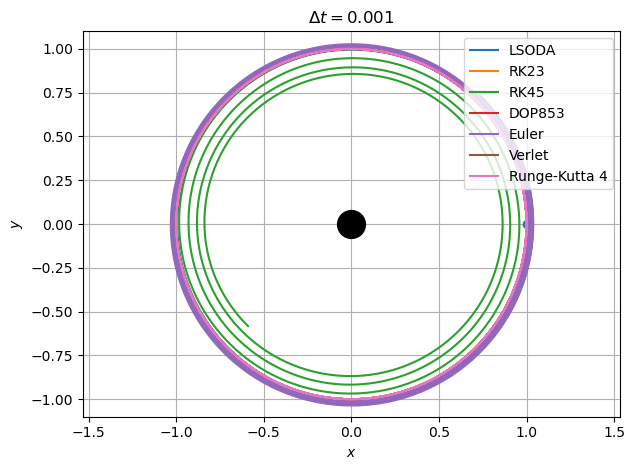

In [6]:
plt.plot(0,0,'ko', markersize=20)
plt.plot(1,0,'C0o')
plt.plot(r[:,0],r[:,1],'-', label=method)
plt.plot(r1[:,0],r1[:,1],'-', label='RK23')
plt.plot(r2[:,0],r2[:,1],'-', label='RK45')
plt.plot(r3[:,0],r3[:,1],'-', label='DOP853')

plt.plot(r_euler[:,0],r_euler[:,1],'-', label='Euler')
plt.plot(r_ver[:,0], r_ver[:,1],label='Verlet')
plt.plot(r_rk[:,0],r_rk[:,1],'-', label='Runge-Kutta 4')

plt.axis('equal')
plt.legend(loc='upper right')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title(f'$\Delta t=${dt}')
plt.xlim((-1.1,1.1))
plt.ylim((-1.1,1.1))
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/v0_{v0}.pdf')

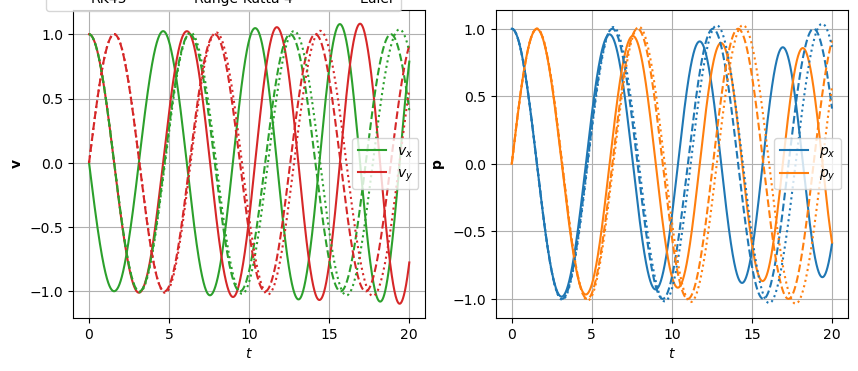

In [7]:
fig = plt.figure(figsize=(10, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])
#plt.subplots_adjust(wspace=0.5)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(t1,v2[:,0],'C2-', label='$v_x$')
ax1.plot(t1,v2[:,1],'C3-', label='$v_y$')
ax1.plot(t,r_rk[:,0],'C2--')
ax1.plot(t,r_rk[:,1],'C3--')
ax1.plot(t,r_euler[:,0],'C2:')
ax1.plot(t,r_euler[:,1],'C3:')

legend = ax1.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='RK45'),
                             plt.Line2D([], [], color='k', linestyle='--', label='Runge-Kutta 4'),
                             plt.Line2D([], [], color='k', linestyle=':', label='Euler')],
                     loc='upper right', bbox_to_anchor=(0.95, 1.1),ncol=3)
plt.gca().add_artist(legend)
ax1.legend()
ax1.set_xlabel('$t$')
ax1.set_ylabel(r'$\mathbf{v}$')
ax1.grid()

ax2 = fig.add_subplot(gs[:, 1])
ax2.plot(t1,r2[:,0],'C0-', label='$p_x$')
ax2.plot(t1,r2[:,1],'C1-', label='$p_y$')
ax2.plot(t,r_rk[:,0],'C0--')
ax2.plot(t,r_rk[:,1],'C1--')
ax2.plot(t,r_euler[:,0],'C0:')
ax2.plot(t,r_euler[:,1],'C1:')

ax2.legend()
ax2.set_xlabel('$t$')
ax2.set_ylabel(r'$\mathbf{p}$')
ax2.grid()
#plt.tight_layout()
#plt.savefig(f'./slike/potek_v_p_v0_1__.pdf')

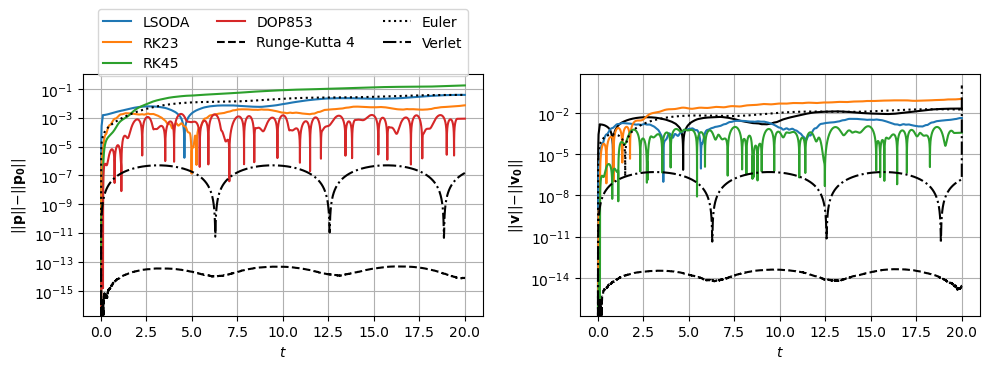

In [8]:
fig = plt.figure(figsize=(10, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])
#plt.subplots_adjust(wspace=0.3)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(t1, abs(r_abs-1), label=method)
ax1.plot(t1, abs(r_abs1-1),label='RK23')
ax1.plot(t1, abs(r_abs2-1),label='RK45')
ax1.plot(t1, abs(r_abs3-1),label='DOP853')

ax1.plot(t, abs(r_abs_rk-1),'k--',label='Runge-Kutta 4')
ax1.plot(t, abs(r_abs_eu-1),'k:',label='Euler')
ax1.plot(t1, abs(r_abs_ver-1),'k-.',label='Verlet')

ax1.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5,1.3))
ax1.grid()
ax1.set_xlabel('$t$')
ax1.set_ylabel(r'||$\mathbf{p}$||$-||\mathbf{p_0}||$')
ax1.set_yscale('log')

ax2 = fig.add_subplot(gs[:, 1])
ax2.plot(t1, abs(v_abs-1),'k-')
ax2.plot(t1, abs(v_abs1-1))
ax2.plot(t1, abs(v_abs2-1))
ax2.plot(t1, abs(v_abs3-1))

ax2.plot(t, abs(v_abs_rk-1),'k--')
ax2.plot(t, abs(v_abs_eu-1),'k:')
ax2.plot(t, abs(v_abs_ver-1),'k-.')

ax2.grid()
ax2.set_xlabel('$t$')
ax2.set_ylabel(r'||$\mathbf{v}$||$-||\mathbf{v_0}||$')
ax2.set_yscale('log')
plt.tight_layout()
#plt.savefig(f'./slike/potek_abs_p_v_v0_{v0}.pdf')

/tmp/ipykernel_89584/2828495192.py:2: RuntimeWarning: divide by zero encountered in divide
  periode = 1/np.fft.fftfreq(len(r[:,0]))[:n//2]
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/aljaz/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


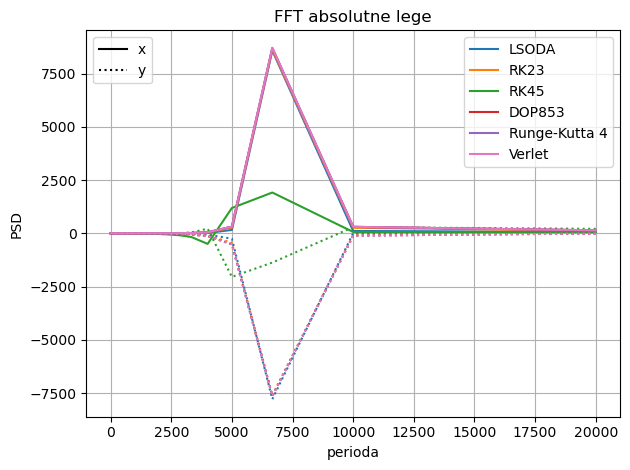

In [9]:
n=len(r[:,0])
periode = 1/np.fft.fftfreq(len(r[:,0]))[:n//2]

r_fft = np.fft.fft2(r[:,:2])[:n//2]**2/n
r_fft1 = np.fft.fft2(r1[:,:2])[:n//2]**2/n
r_fft2 = np.fft.fft2(r2[:,:2])[:n//2]**2/n
r_fft3 = np.fft.fft2(r3[:,:2])[:n//2]**2/n
r_fft_rk = np.fft.fft2(r_rk[:,:2])[:n//2]**2/n
r_fft_eu = np.fft.fft2(r_euler[:,:2])[:n//2]**2/n
r_fft_ver = np.fft.fft2(r_ver[:,:2])[:n//2]**2/n

plt.plot(periode, r_fft[:,0], 'C0-',label=method)
plt.plot(periode, r_fft[:,1], 'C0:')
plt.plot(periode, r_fft1[:,0], 'C1-',label='RK23')
plt.plot(periode, r_fft1[:,1], 'C1:')
plt.plot(periode, r_fft2[:,0], 'C2-',label='RK45')
plt.plot(periode, r_fft2[:,1], 'C2:')
plt.plot(periode, r_fft3[:,0], 'C3-',label='DOP853')
plt.plot(periode, r_fft3[:,1], 'C3:')
plt.plot(periode, r_fft_rk[:,0], 'C4-',label='Runge-Kutta 4')
plt.plot(periode, r_fft_rk[:,1], 'C4:')
# plt.plot(periode, r_fft_eu[:,0], 'C5-',label='Euler')
# plt.plot(periode, r_fft_eu[:,1], 'C5:')
plt.plot(periode, r_fft_ver[:,0], 'C6-',label='Verlet')
plt.plot(periode, r_fft_ver[:,1], 'C6:')

legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='x'),
                                         plt.Line2D([], [], color='k', linestyle=':', label='y')],
                                loc='upper left', ncol=1)
plt.gca().add_artist(legend_line_styles)
plt.legend()
plt.grid()
plt.xlabel('perioda')
plt.ylabel('PSD')
plt.title('FFT absolutne lege')
plt.tight_layout()
#plt.savefig(f'./slike/fft_lege_v0_{v0}.pdf')

/tmp/ipykernel_89584/2684444854.py:2: RuntimeWarning: divide by zero encountered in divide
  periode = 1/np.fft.fftfreq(len(r_abs))[:n//2]


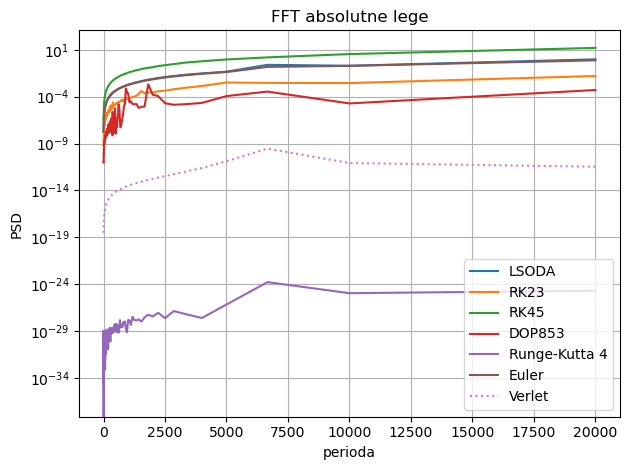

In [10]:
n=len(r_abs)
periode = 1/np.fft.fftfreq(len(r_abs))[:n//2]

r_fft = np.fft.fft(r_abs)[:n//2]**2/n
r_fft1 = np.fft.fft(r_abs1)[:n//2]**2/n
r_fft2 = np.fft.fft(r_abs2)[:n//2]**2/n
r_fft3 = np.fft.fft(r_abs3)[:n//2]**2/n
r_fft_rk = np.fft.fft(r_abs_rk)[:n//2]**2/n
r_fft_eu = np.fft.fft(r_abs_eu)[:n//2]**2/n
r_fft_ver = np.fft.fft(r_abs_ver)[:n//2]**2/n

plt.plot(periode, abs(r_fft), 'C0-',label=method)
plt.plot(periode, abs(r_fft1), 'C1-',label='RK23')
plt.plot(periode, abs(r_fft2), 'C2-',label='RK45')
plt.plot(periode, abs(r_fft3), 'C3-',label='DOP853')
plt.plot(periode, abs(r_fft_rk), 'C4-',label='Runge-Kutta 4')
plt.plot(periode, abs(r_fft_eu), 'C5-',label='Euler')
plt.plot(periode, abs(r_fft_ver), 'C6:',label='Verlet')

plt.yscale('log')
plt.legend()
plt.grid()
plt.xlabel('perioda')
plt.ylabel('PSD')
plt.title('FFT absolutne lege')
plt.tight_layout()
#plt.savefig(f'./slike/fft_abs_lege_v0_{v0}.pdf')

/tmp/ipykernel_89584/130663804.py:2: RuntimeWarning: divide by zero encountered in divide
  periode = 1/np.fft.fftfreq(len(v[:,0]))[:n//2]


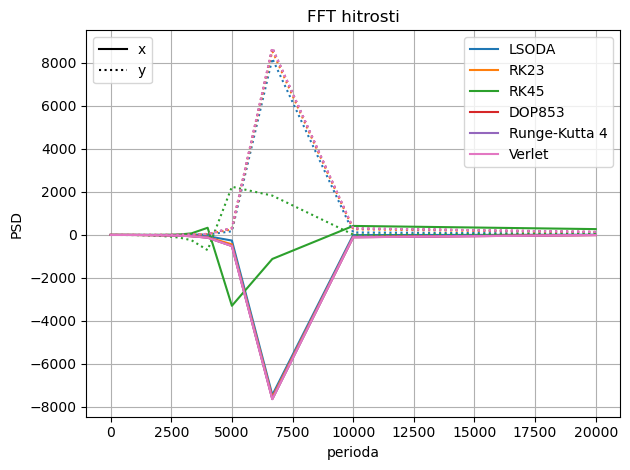

In [11]:
n=len(v[:,0])
periode = 1/np.fft.fftfreq(len(v[:,0]))[:n//2]

r_fft = np.fft.fft2(v[:,:2])[:n//2]**2/n
r_fft1 = np.fft.fft2(v1[:,:2])[:n//2]**2/n
r_fft2 = np.fft.fft2(v2[:,:2])[:n//2]**2/n
r_fft3 = np.fft.fft2(v3[:,:2])[:n//2]**2/n
r_fft_rk = np.fft.fft2(v_rk[:,:2])[:n//2]**2/n
r_fft_eu = np.fft.fft2(v_euler[:,:2])[:n//2]**2/n
r_fft_ver = np.fft.fft2(v_ver[:,:2])[:n//2]**2/n

plt.plot(periode, r_fft[:,0], 'C0-',label=method)
plt.plot(periode, r_fft[:,1], 'C0:')
plt.plot(periode, r_fft1[:,0], 'C1-',label='RK23')
plt.plot(periode, r_fft1[:,1], 'C1:')
plt.plot(periode, r_fft2[:,0], 'C2-',label='RK45')
plt.plot(periode, r_fft2[:,1], 'C2:')
plt.plot(periode, r_fft3[:,0], 'C3-',label='DOP853')
plt.plot(periode, r_fft3[:,1], 'C3:')
plt.plot(periode, r_fft_rk[:,0], 'C4-',label='Runge-Kutta 4')
plt.plot(periode, r_fft_rk[:,1], 'C4:')
# plt.plot(periode, r_fft_eu[:,0], 'C5-',label='Euler')
# plt.plot(periode, r_fft_eu[:,1], 'C5:')
plt.plot(periode, r_fft_ver[:,0], 'C6-',label='Verlet')
plt.plot(periode, r_fft_ver[:,1], 'C6:')

legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='x'),
                                         plt.Line2D([], [], color='k', linestyle=':', label='y')],
                                loc='upper left', ncol=1)
plt.gca().add_artist(legend_line_styles)
plt.legend()
plt.grid()
plt.xlabel('perioda')
plt.ylabel('PSD')
plt.title('FFT hitrosti')
plt.tight_layout()
#plt.savefig(f'./slike/fft_hitr_v0_{v0}.pdf')

/tmp/ipykernel_89584/1540646358.py:2: RuntimeWarning: divide by zero encountered in divide
  periode = 1/np.fft.fftfreq(len(v_abs))[:n//2]


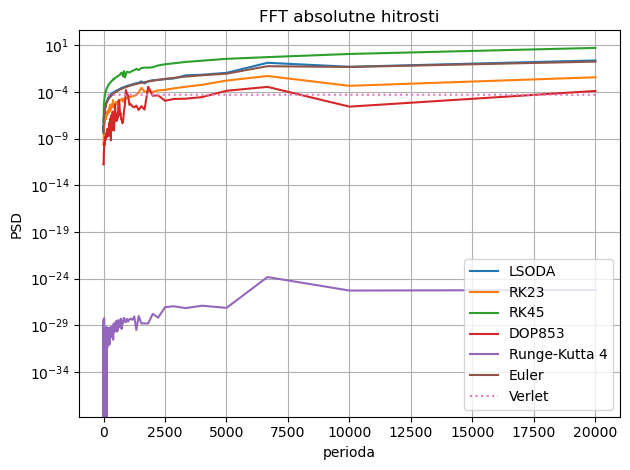

In [12]:
n=len(v_abs)
periode = 1/np.fft.fftfreq(len(v_abs))[:n//2]

r_fft = np.fft.fft(v_abs)[:n//2]**2/n
r_fft1 = np.fft.fft(v_abs1)[:n//2]**2/n
r_fft2 = np.fft.fft(v_abs2)[:n//2]**2/n
r_fft3 = np.fft.fft(v_abs3)[:n//2]**2/n
r_fft_rk = np.fft.fft(v_abs_rk)[:n//2]**2/n
r_fft_eu = np.fft.fft(v_abs_eu)[:n//2]**2/n
r_fft_ver = np.fft.fft(v_abs_ver)[:n//2]**2/n

plt.plot(periode, abs(r_fft), 'C0-',label=method)
plt.plot(periode, abs(r_fft1), 'C1-',label='RK23')
plt.plot(periode, abs(r_fft2), 'C2-',label='RK45')
plt.plot(periode, abs(r_fft3), 'C3-',label='DOP853')
plt.plot(periode, abs(r_fft_rk), 'C4-',label='Runge-Kutta 4')
plt.plot(periode, abs(r_fft_eu), 'C5-',label='Euler')
plt.plot(periode, abs(r_fft_ver), 'C6:',label='Verlet')

plt.yscale('log')
plt.legend()
plt.grid()
plt.xlabel('perioda')
plt.ylabel('PSD')
plt.title('FFT absolutne hitrosti')
plt.tight_layout()
#plt.savefig(f'./slike/fft_abs_hitr_v0_{v0}.pdf')

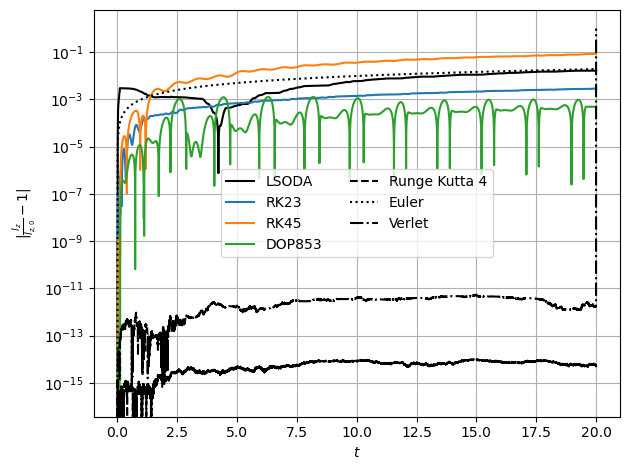

In [13]:
plt.plot(t1, abs(l[:,2]/l[0,2]-1), 'k-', label=method)
plt.plot(t1, abs(l1[:,2]/l1[0,2]-1), label='RK23')
plt.plot(t1, abs(l2[:,2]/l2[0,2]-1), label='RK45')
plt.plot(t1, abs(l3[:,2]/l3[0,2]-1), label='DOP853')

plt.plot(t, abs(l_rk[:,2]/l_rk[0,2]-1), 'k--', label='Runge Kutta 4')
plt.plot(t, abs(l_eu[:,2]/l_eu[0,2]-1), 'k:', label='Euler')
plt.plot(t, abs(l_ver[:,2]/l_ver[0,2]-1), 'k-.', label='Verlet')

plt.xlabel('$t$')
plt.ylabel('|$\\frac{l_z}{l_{z,0}} -1$|')
plt.yscale('log')
plt.legend(ncol=2)
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/potek_lz_v0_{v0}.pdf')

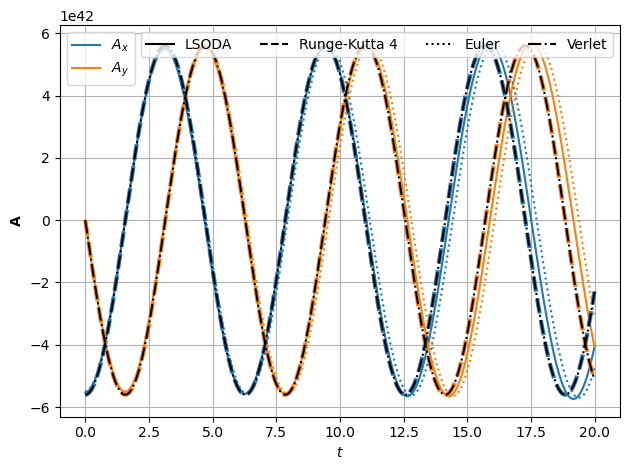

In [14]:
plt.plot(t1,A[:,0],'C0-',label='$A_x$')
plt.plot(t1,A[:,1],'C1-',label='$A_y$')

plt.plot(t,A_rk[:,0],'C0--', linewidth=3)
plt.plot(t,A_rk[:,1],'C1--', linewidth=3)

plt.plot(t,A_eu[:,0],'C0:')
plt.plot(t,A_eu[:,1],'C1:')

plt.plot(t,A_ver[:,0],'k-.')
plt.plot(t,A_ver[:,1],'k-.')

legend = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label=method),
                             plt.Line2D([], [], color='k', linestyle='--', label='Runge-Kutta 4'),
                             plt.Line2D([], [], color='k', linestyle=':', label='Euler'),
                             plt.Line2D([], [], color='k', linestyle='-.', label='Verlet')],
                     loc='upper right', ncol=4)
plt.gca().add_artist(legend)
plt.legend(loc='best')
plt.xlabel('$t$')
plt.ylabel('$\mathbf{A}$')
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/potek_A_v0_{v0}.pdf')

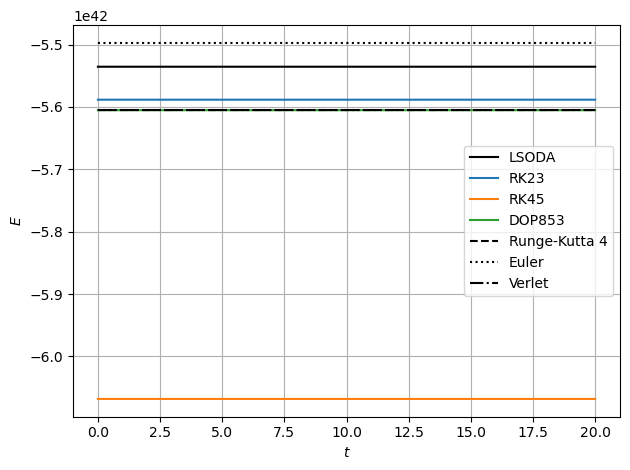

In [15]:
plt.plot(t1,E,'k-', label=method)
plt.plot(t1,E1, label='RK23')
plt.plot(t1,E2, label='RK45')
plt.plot(t1,E3, label='DOP853')
plt.plot(t,E_rk,'k--', label='Runge-Kutta 4')
plt.plot(t,E_eu,'k:', label='Euler')
plt.plot(t,E_ver,'k-.', label='Verlet')

plt.legend()
plt.xlabel('$t$')
plt.ylabel('$E$')
plt.grid()
#plt.yscale('symlog')
plt.tight_layout()
#plt.savefig(f'./slike/E_v0_{v0}.pdf')

### 3 planeti

In [16]:
def kepler2(t,y,*args):
    '''3 objekti le gravitacija sonca'''
    x2 = - y[0] /(y[0]**2 + y[1]**2)**(3/2)#zemlja
    x3 = - y[1] /(y[0]**2 + y[1]**2)**(3/2)
    x6 = - y[4] /(y[5]**2 + y[4]**2)**(3/2)#lega satelita v KS sonca
    x7 = - y[5] /(y[5]**2 + y[4]**2)**(3/2)
    return np.array([y[2], y[3] ,x2, x3, y[6], y[7], x6, x7])
def kepler3(t,y,*args):
    '''3 objekti popolna odvisnost - tudi gravitac. polje zemlje na satelit'''
    k,k2 = args #k=m_earth/m_sun, k2 = m_satelit/m_sun
    r_sz = np.zeros(2) #razdalja satelit-zemlja, podatki y[4,5]: satelit-sonce!
    r_sz[0] = -y[0]+y[4]
    r_sz[1] = -y[1]+y[5]
    #zemlja; G*M = 1
    x2 = - y[0] /(y[0]**2 + y[1]**2)**(3/2) #- k2*r_sz[0] /(r_sz[0]**2 + r_sz[1]**2)**(3/2) #zanemari!
    x3 = - y[1] /(y[0]**2 + y[1]**2)**(3/2) #- k2*r_sz[1] /(r_sz[0]**2 + r_sz[1]**2)**(3/2)
    #satelit
    x6 = - y[4] /(y[5]**2 + y[4]**2)**(3/2) - k*r_sz[0] /(r_sz[0]**2 + r_sz[1]**2)**(3/2)
    x7 = - y[5] /(y[5]**2 + y[4]**2)**(3/2) - k*r_sz[1] /(r_sz[0]**2 + r_sz[1]**2)**(3/2)
    return np.array([y[2], y[3] ,x2, x3, y[6], y[7], x6, x7])

In [131]:
method = 'DOP853' #RK23,RK45,DOP853; implicit:Radau,BDF,LSODA
v0 = 1
v0s= 1.5 # pade nazaj? tir elipse pri v0=0, mali v0 - problemi!!!
#v0s= 0.5 # vmes tir elipse - kje krožnice?
#v0s= 1 # v0s=1: parabola; več: hipebola
M = m_sun
m = m_earth
k = m_earth/m_sun
k2= 100000/m_sun #zanemarim maso satelita - kg: k2 -> 0!
dt=0.001
t_min, t_max = 0, 10

t = np.arange(t_min, t_max, dt)
y0 = np.array([1, 0, 0, v0, 1+10**(-3), 0, v0s, v0]) #x0,y0,vx0,vy0

# res2 = solve_ivp(kepler3, t_span=(t_min, t_max), y0=y0, method=method, args=(k,k2)) #avtomatski dt!
# #res2 = solve_ivp(kepler3, t_span=(t_min, t_max), y0=y0, method=method, args=(k,k2), t_eval=t)
# y = res2.y
# t1 = res2.t

#slavič
#y_eu = euler(kepler3, t, y0, k,k2)
y = runge_kutta_4(kepler3, t, y0, k,k2)

r_abs = np.sqrt(y[0]**2+y[1]**2)
v_abs = np.sqrt(y[2]**2+y[3]**2)

r = np.array([(i,j,0) for i,j in zip(y[0],y[1])])
v = np.array([(i,j,0) for i,j in zip(y[2],y[3])])
r_s = np.array([(i,j,0) for i,j in zip(y[4],y[5])])
v_s = np.array([(i,j,0) for i,j in zip(y[6],y[7])])

E = energija(m, M, r, v)
A,l = runge_lenz(m,M,r,v)

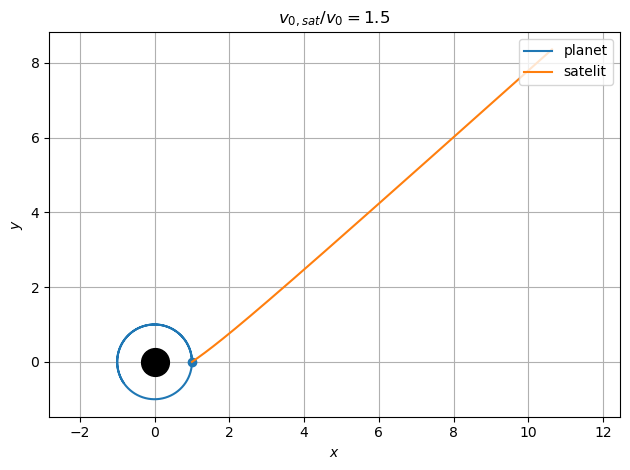

In [133]:
plt.plot(0,0,'ko', markersize=20)
plt.plot(1,0,'C0o')
plt.plot(r[:,0],r[:,1],'-', label='planet')
plt.plot(r_s[:,0],r_s[:,1],'-', label='satelit')
plt.axis('equal')
plt.legend(loc='upper right')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title(f'$v_{{0,sat}}/v_0=${v0s/v0}')
# plt.xlim((-1.2,1.2))
# plt.ylim((-1.2,1.2))
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/satelit_v{v0s}.pdf')

# dvojno sonce

In [12]:
def dvojno(t,y,*args):
    '''dvojno sonce istih mas na razdalji R'''
    #sonce1
    xi = (y[0]-y[4])
    yi = (y[1]-y[5])
    x2 = - xi /(xi**2 + yi**2)**(3/2)
    x3 = - yi /(xi**2 + yi**2)**(3/2)
    #sonce2
    xi = (y[4]-y[0])
    yi = (y[5]-y[1])
    x6 = - xi /(xi**2 + yi**2)**(3/2)
    x7 = - yi /(xi**2 + yi**2)**(3/2)
    return np.array([y[2], y[3] ,x2, x3, y[6], y[7], x6, x7])
def planet(t,y,*args):
    '''planet okoli dvojnega sonca- poenostavljen problem 3 teles'''
    #sonce1
    xi = (y[0]-y[4])
    yi = (y[1]-y[5])
    x2 = - xi /(xi**2 + yi**2)**(3/2) #zanemarimo vpliv planeta na sonci!
    x3 = - yi /(xi**2 + yi**2)**(3/2)
    #sonce2
    xi = (y[4]-y[0])
    yi = (y[5]-y[1])
    x6 = - xi /(xi**2 + yi**2)**(3/2)
    x7 = - yi /(xi**2 + yi**2)**(3/2)
    #planet
    xi1,xi2 = (y[8]-y[0]), (y[8]-y[4])
    yi1,yi2 = (y[9]-y[1]), (y[9]-y[5])
    x10 = - xi1/2 /(xi1**2 + yi1**2)**(3/2) - xi2/2 /(xi2**2 + yi2**2)**(3/2)
    x11 = - yi1/2 /(xi1**2 + yi1**2)**(3/2) - yi2/2 /(xi2**2 + yi2**2)**(3/2)
    return np.array([y[2], y[3] ,x2, x3, y[6], y[7], x6, x7, y[10], y[11], x10, x11])

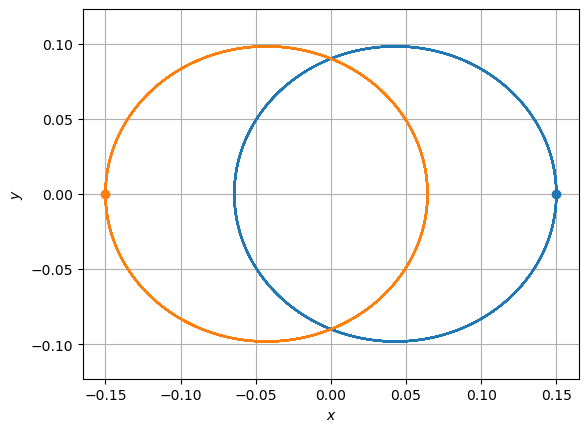

In [13]:
#dvojno sonce
v0 = 1
R = 0.3 #razdalja med soncema -> orbita! če R=0.5 se prekriva

dt=0.001
t_min, t_max = 0, 3
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0])

y = runge_kutta_4(dvojno, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[0,0],r[0,1])
plt.plot(r[1,0],r[1,1])
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid()

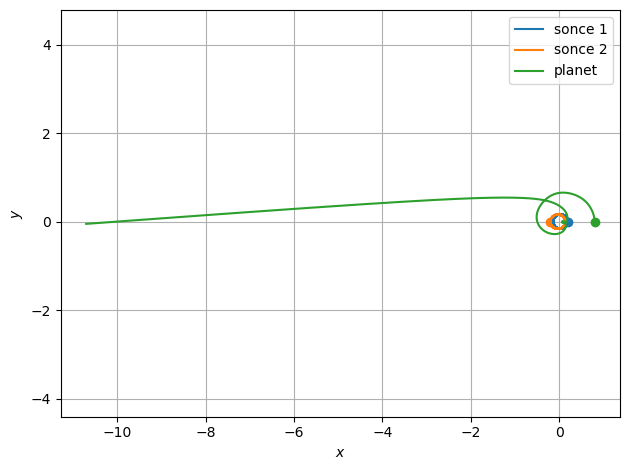

In [14]:
v0 = 1
R = 0.4 #razdalja med soncema -> orbita! če R=0.5 se prekriva
R_p = 2*R #odmik planeta
v0p = v0 #hitrost planeta

dt=0.001
t_min, t_max = 0, 10
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0, R_p,0, 0,v0p])

y = runge_kutta_4(planet, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2o')
plt.plot(r[0,0],r[0,1],label='sonce 1')
plt.plot(r[1,0],r[1,1],label='sonce 2')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend(loc='upper right')
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/planet_R{R_p}.pdf')

### L1

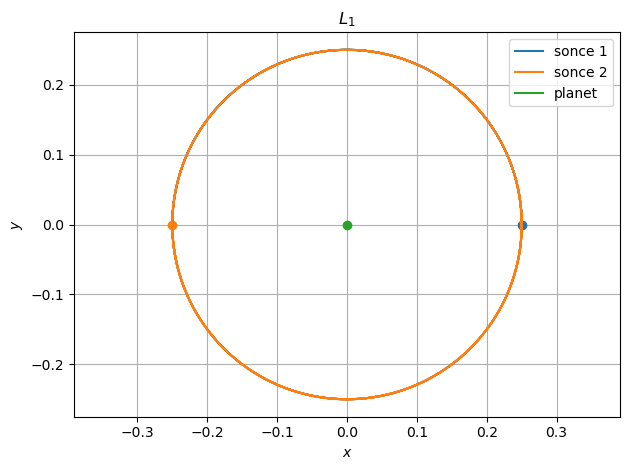

In [15]:
v0 = 1
R = 0.5 #razdalja med soncema -> orbita! če R=0.5 se prekriva
R_p = 0 #odmik planeta
v0p = 0 #hitrost planeta

dt=0.01
t_min, t_max = 0, 4
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0, R_p,0, v0p,v0p])

y = runge_kutta_4(planet, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2o')
plt.plot(r[0,0],r[0,1],label='sonce 1')
plt.plot(r[1,0],r[1,1],label='sonce 2')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('$L_1$')
plt.legend(loc='upper right')
plt.grid()
plt.tight_layout()
#plt.savefig('./slike/L1.pdf')

### L2

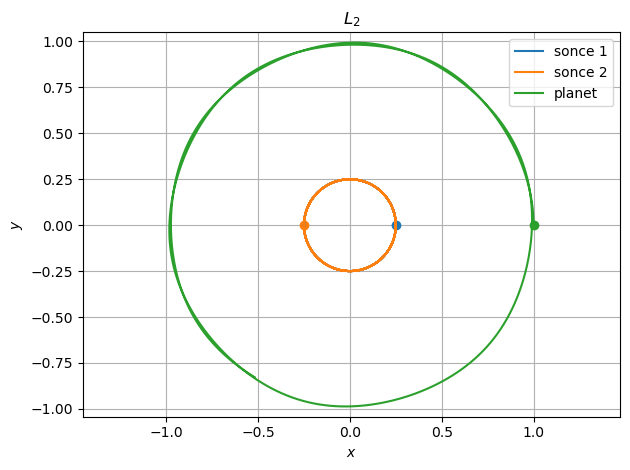

In [16]:
v0 = 1
R = 0.5 #razdalja med soncema -> orbita! če R=0.5 se prekriva
R_p = 2*R #odmik planeta
v0p = v0 #hitrost planeta

dt=0.01
t_min, t_max = 0, 10
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0, R_p,0, 0,v0p])

y = runge_kutta_4(planet, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2o')
plt.plot(r[0,0],r[0,1],label='sonce 1')
plt.plot(r[1,0],r[1,1],label='sonce 2')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('$L_2$')
plt.legend(loc='upper right')
plt.grid()
plt.tight_layout()
#plt.savefig('./slike/L2.pdf')

### L3

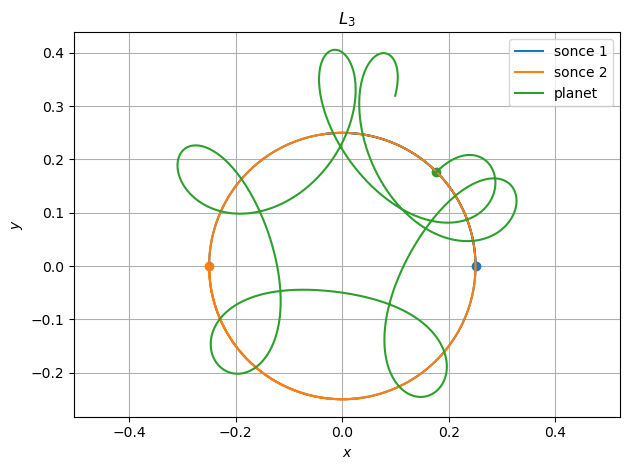

In [17]:
#lahko spreminjamo (malo) tudi razdaljo med soncema R!
v0 = 1
R = 0.5 #razdalja med soncema -> orbita! če R=0.5 se prekriva
R_p = R/2/np.sqrt(2) #odmik planeta # spreminjaj koren!!!
v0p = v0 #hitrost planeta

dt=0.001
t_min, t_max = 0, 2
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0, R_p,R_p, v0p,v0p])

y = runge_kutta_4(planet, t, y0)
#y = verlet(planet, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2o')
plt.plot(r[0,0],r[0,1],label='sonce 1')
plt.plot(r[1,0],r[1,1],label='sonce 2')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('$L_3$')
plt.legend(loc='upper right')
plt.grid()
plt.tight_layout()
#plt.savefig('./slike/L3_.pdf')

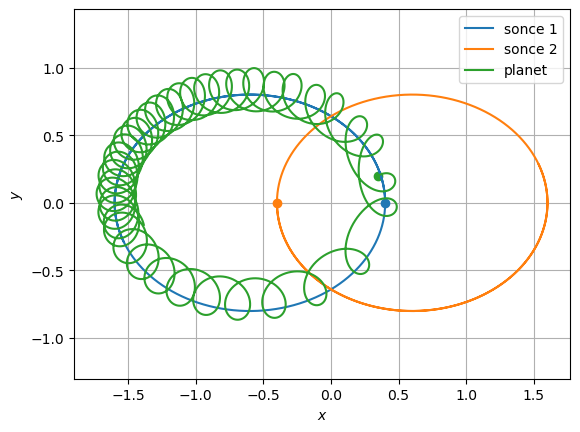

In [18]:
v0 = 1
R = 0.8 #razdalja med soncema -> orbita! če R=0.5 se prekriva
kot = np.pi/6 #pi/4 in /5 stabilno!
R_p1,R_p2 = R/2*np.cos(kot), R/2*np.sin(kot) #odmik planeta
v0p = 2**0.5#2*v0 #hitrost planeta
v0p1, v0p2 = v0p*np.cos(kot), v0p*np.sin(kot) #radialno!

dt=0.001
t_min, t_max = 0, 20
t = np.arange(t_min, t_max, dt)
y0 = np.array([R/2,0, 0,v0, -R/2,0, 0,-v0, R_p1,R_p2, v0p1,v0p2])

y = runge_kutta_4(planet, t, y0)
r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])

plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2o')
plt.plot(r[0,0],r[0,1],label='sonce 1')
plt.plot(r[1,0],r[1,1],label='sonce 2')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend(loc='upper right')
plt.grid()

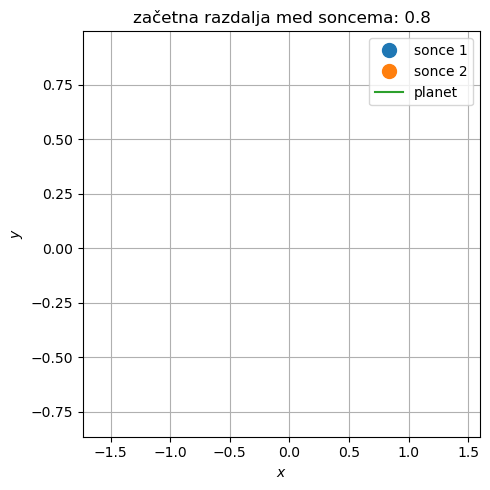

In [19]:
# Create a figure and axis
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
#ax.set_title(f'začetna lega pod kotom $\pi/{int(1/(kot/np.pi))}$˚')
ax.set_title(f'začetna razdalja med soncema: {R}')
ax.grid(True)

# Initialize empty scatter plots for each planet
scatters = [ax.plot([], [], 'o', label=label, markersize=10)[0] for label in ['sonce 1', 'sonce 2']]
scatters.extend(ax.plot([], [], '-', label=label, markersize=1)[0] for label in ['planet'])

# Data
resize_factor = 3
data = r[:, :, ::resize_factor]
n = data.shape[2]

# Create animation
ani = FuncAnimation(fig, update, frames=n, init_func=init, blit=True)

# Set appropriate limits for the axes based on the data range
x_min, x_max = np.min(r[:, 0, :]), np.max(r[:, 0, :])
y_min, y_max = np.min(r[:, 1, :]), np.max(r[:, 1, :])

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
#ax.axis('equal') #pokveče

plt.legend(loc='upper right')
plt.tight_layout()
#ani.save(f'slike/trajectory_angle{int(1/(kot/np.pi))}_R{R}.mp4', fps=60, extra_args=['-vcodec', 'libx264'])
plt.show()

# zvezda

In [111]:
def zvezda(t,y,*args):
    '''zanemarimo y-pomik zvezde. to je poenostevljen primer funkcije planet'''
    #sonce
    xi = (y[0]-y[4])
    yi = (y[1]-y[5])
    x2 = y[2] #- xi /(xi**2 + yi**2)**(3/2) #zanemarimo vpliv planeta na sonci!
    x3 = y[3] #- yi /(xi**2 + yi**2)**(3/2)
    #zvezda
    xi = (y[4]-y[0])
    yi = (y[5]-y[1])
    x6 = y[6] #- xi /(xi**2 + yi**2)**(3/2)
    x7 = y[7] #- yi /(xi**2 + yi**2)**(3/2)
    #planet
    xi1,xi2 = (y[8]-y[0]), (y[8]-y[4])
    yi1,yi2 = (y[9]-y[1]), (y[9]-y[5])
    x10 = - xi1/2 /(xi1**2 + yi1**2)**(3/2) - xi2/2 /(xi2**2 + yi2**2)**(3/2)
    x11 = - yi1/2 /(xi1**2 + yi1**2)**(3/2) - yi2/2 /(xi2**2 + yi2**2)**(3/2)
    return np.array([y[2], y[3] ,x2, x3, y[6], y[7], x6, x7, y[10], y[11], x10, x11])
def mimobezna(kot, dt=1, t_max=100, R=1,v0=1):
    #R = 1 #razdalja sonce-planet
    #v0 = 0.25 #hitrost planeta
    R_p1,R_p2 = R*np.cos(kot), R*np.sin(kot) #odmik planeta
    vp1, vp2 = v0*np.cos(kot+np.pi/2), v0*np.sin(kot+np.pi/2)
    #print(vp1,vp2, np.sqrt(vp1**2+vp2**2))

    t_min=0
    t = np.arange(t_min, t_max, dt)
    y0 = np.array([0,0, 0,0, -10*R,1.5*R, 2*v0,0, R_p1,R_p2, vp1,vp2])

    #y = runge_kutta_4(planet, t, y0) #vseeno zanemarjen vpliv planeta na sonce, zvezdo!
    #y = runge_kutta_4(zvezda, t, y0) #zanemarjen vpliv sonce-zvezda
    res = solve_ivp(planet, t_span=(t_min, t_max), y0=y0, method='RK23',max_step=dt) #auto dt!
    y = res.y
    t = res.t
    
    r = np.array([[y[0],y[1]],[y[4],y[5]],[y[8],y[9]]])
    v = np.array([[y[2],y[3]],[y[6],y[7]],[y[10],y[11]]])

    masa = [m_sun, m_sun, m_earth]
    E=0
    l=0
    for i in range(0,3):
        mi = masa[i]
        ri = np.transpose([r[i,0],r[i,1],np.zeros_like(r[i,0])])
        vi = np.transpose([v[i,0],v[i,1],np.zeros_like(v[i,0])])
        l += vrtilna(m=mi,r=ri, v=vi)
        for j in range(0,3):
            if i!=j and i>j:
                ri = np.transpose([r[i,0]-r[j,0], r[i,1]-r[j,1], np.zeros_like(r[i,0])])
                vi = np.transpose([v[i,0]-v[j,0], v[i,1]-v[j,1], np.zeros_like(v[i,0])])
                mj = masa[j]
                E += energija(m=mi, M=mj,r=ri,v=vi)
    return r,v, E, l, t

RAVNOVESJE: 
 vrtilna: -1.493928181004199e+30 
 energija: -2.254032219946074e+47


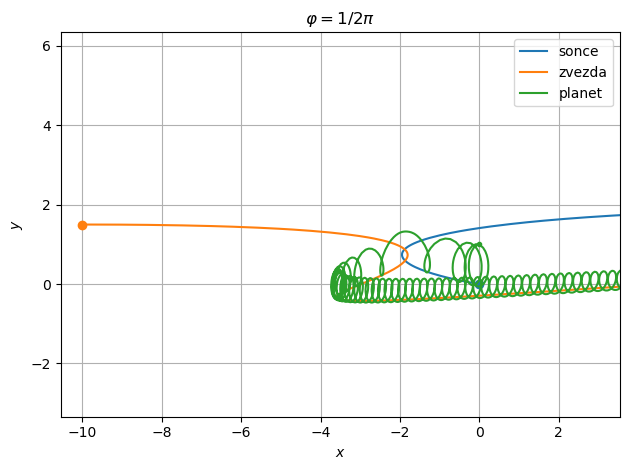

In [194]:
# kot = np.pi/2
# r,v,E,l,t = mimobezna(kot)

#sonce-zvezda
# ri = r[0] - r[1]
# vi = v[0] - v[1]
# E1 = energija(m=m_earth, M=m_sun,r=ri,v=vi)
# masa = [m_sun, m_sun, m_earth]
# E=0
# l=0
# for i in range(0,3):
#     ri = np.transpose([r[i,0],r[i,1],np.zeros_like(r[i,0])])
#     vi = np.transpose([v[i,0],v[i,1],np.zeros_like(v[i,0])])
#     l += vrtilna(m=mi,r=ri, v=vi)
#     for j in range(0,3):
#         if i!=j and i>j:
#             print(i,j)
#             ri = r[i] - r[j]
#             vi = v[i] - v[j]
#             mi, mj = masa[i], masa[j]
#             E += energija(m=mi, M=mj,r=ri,v=vi)

kot = 1*np.pi/2
#kot = koti[39]
v0=0.25 #default 1, manj bolj zanimivo, min 0.25
r,v,E,l,t = mimobezna(kot, t_max=150, dt=1,v0=v0)
fraction = Fraction((kot/np.pi)).limit_denominator()

plt.title(f'$\\varphi={{{fraction}}} \pi$')
plt.plot(r[0,0,0], r[0,1,0],'C0o')
plt.plot(r[1,0,0], r[1,1,0],'C1o')
plt.plot(r[2,0,0], r[2,1,0],'C2.')
plt.plot(r[0,0],r[0,1],label='sonce')
plt.plot(r[1,0],r[1,1],label='zvezda')
plt.plot(r[2,0],r[2,1],label='planet')
plt.axis('equal')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend(loc='upper right')
plt.xlim(-10,3)
plt.ylim(0,3)
plt.grid()
plt.tight_layout()
#plt.savefig(f'./slike/tir_phi0_{kot/np.pi:.2f}_v0.pdf') #če ni napisano, je v0=0.5!
#plt.savefig(f'./slike/kot_max_E_v0_{v0}.pdf')

print('RAVNOVESJE: \n vrtilna:',l[-1,2], '\n energija:', E[-1])
#plt.plot(t,l[:,2])
#plt.plot(t,E[:]) #konst!

In [107]:
l=[]
E=[]
v=[]
r=[]
d=np.pi/30
koti=np.arange(d,d+2*np.pi,d)

dt = 0.01
t_max = 50
v0 = 0.5
for kot in koti:
    ri,vi,Ei,li,t = mimobezna(kot,t_max=t_max,dt=dt,v0=v0)
    E.append(Ei[-1])
    l.append(li[-1,2])
    r.append(ri)
    #v.append(vi)
l=np.array(l)
E=np.array(E)
# v=np.array(r)
r=np.array(r)

In [108]:
np.max(E)/E[-1], np.argmax(E), E[39]/E[-1], koti[39] #rad

(0.9999964799026849, 27, 1.0000305645705312, 4.1887902047863905)

Text(0.5, 1.0, '$v_{p0}=$0.5')

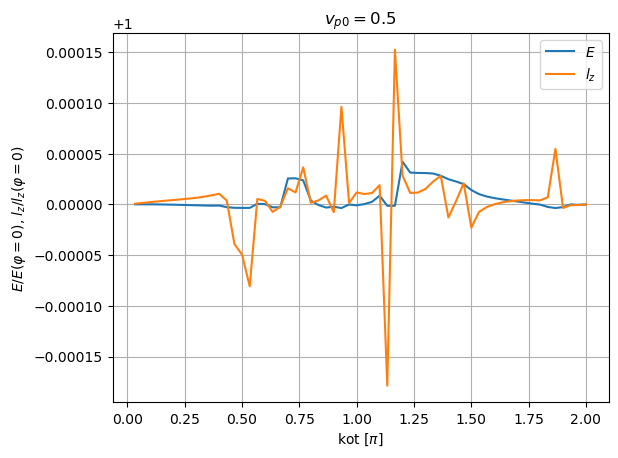

In [109]:
plt.plot(koti/np.pi,E/E[-1], '-',label='$E$')
plt.plot(koti/np.pi,l/l[-1], '-',label='$l_z$')
plt.xlabel('kot [$\pi$]')
plt.ylabel('$E/E(\\varphi=0)$, $l_z/l_z(\\varphi=0)$')
plt.legend()
plt.grid()
plt.title(f'$v_{{p0}}=${v0}')
#plt.savefig(f'./slike/energija_kot_zvezda_v0_{v0}.pdf')

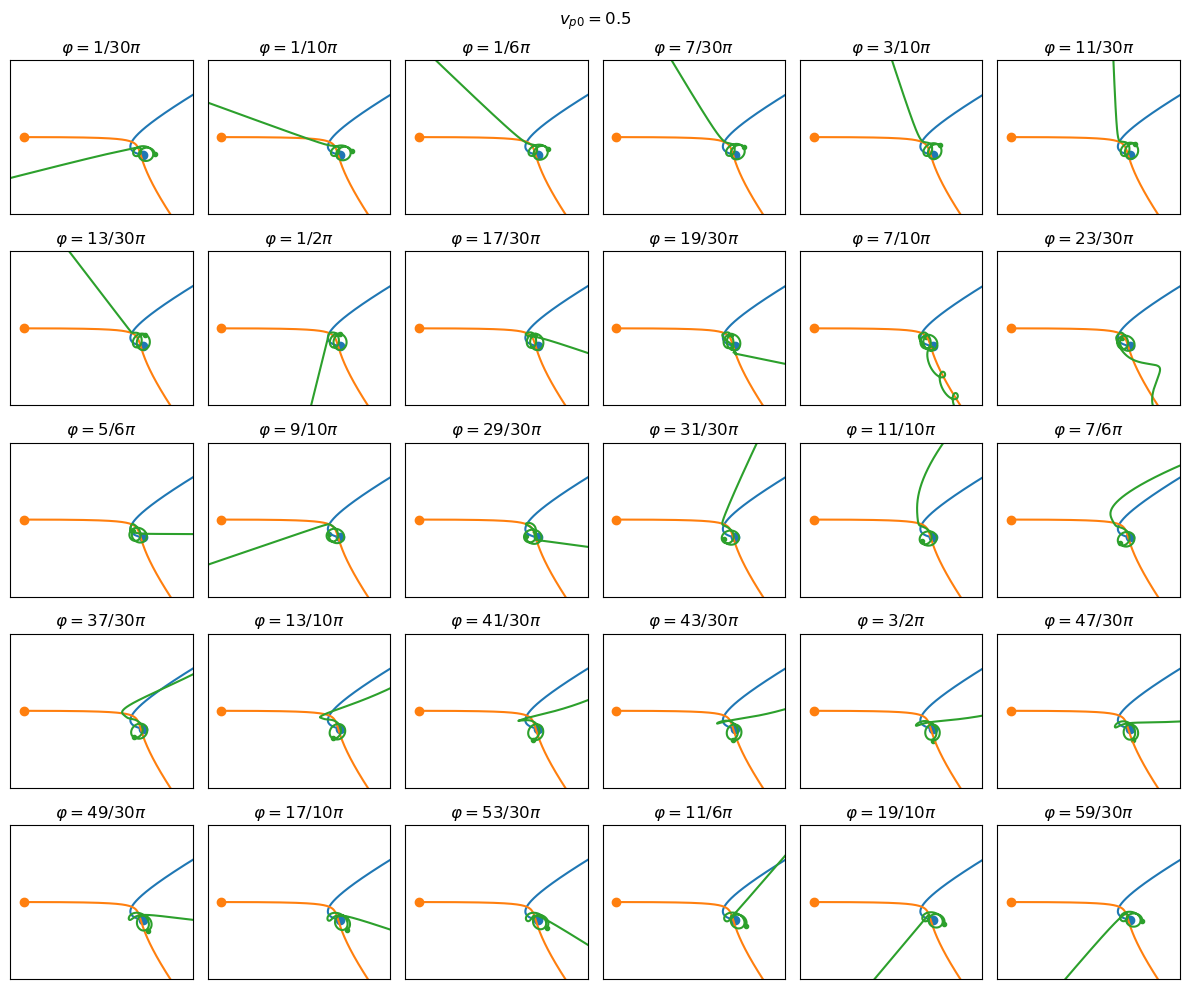

In [110]:
kot = np.pi/6
i=np.where(np.isclose(koti/np.pi,kot/np.pi))

d = 2 #korak prikaz
n = int(np.ceil(np.sqrt(len(koti)//d//2)))+d

fig = plt.figure(figsize=(n*2,n*2))
gs = plt.GridSpec(nrows=n, ncols=n)

for i in range(0,len(koti), d):
    j = i//d
    plt.subplot(gs[j])
    plt.plot(r[i,0,0,0], r[i,0,1,0],'C0o') #r[kot_i, planet, os, čas]
    plt.plot(r[i,1,0,0], r[i,1,1,0],'C1o')
    plt.plot(r[i,2,0,0], r[i,2,1,0],'C2.')
    plt.plot(np.squeeze(r[i,0,0]), np.squeeze(r[i,0,1]), label='sonce')
    plt.plot(np.squeeze(r[i,1,0]), np.squeeze(r[i,1,1]), label='zvezda')
    plt.plot(np.squeeze(r[i,2,0]), np.squeeze(r[i,2,1]), label='planet')
    plt.axis('equal')
    plt.xticks([])
    plt.yticks([])
    ulomek=int(1/(koti[i]/np.pi))
    fraction = Fraction((koti[i]/np.pi)).limit_denominator()
    plt.title(f'$\\varphi={{{fraction}}} \pi$')
    plt.xlim(-10,3)
    plt.ylim(0,3)
plt.suptitle(f'$v_{{p0}}=${v0}')
plt.tight_layout()
#plt.savefig(f'./slike/koti_potek_v0_{v0}.pdf')

# 2d plot

In [140]:
l=[]
E=[]
v=[]
r=[]
dt_max=10
d=np.pi/100
koti=np.arange(d,d+2*np.pi,d)
v0_max = 1
dv = 0.005
v0_list = np.arange(0.1, v0_max,dv)
print(len(koti),len(v0_list))
i=0
n_iter=len(v0_list)*len(koti)
for v0 in v0_list:
    print(f'iteracije: {i}/{n_iter}', end='\r')
    EE=[]
    ll=[]
    #rr=[]
    #vv=[]
    for kot in koti:
        i+=1
        ri,vi,Ei,li,t = mimobezna(kot,t_max=50,v0=v0,dt=dt_max) #spremeni v solve_ivp!
        EE.append(Ei[-1])
        ll.append(li[-1,2])
        #rr.append(ri)
        #vv.append(vi)
    E.append(EE/EE[-1]-1)
    l.append(ll/ll[-1]-1)
    #r.append(rr)
    #v.append(vv)
print(f'iteracije: {i}/{n_iter}', end='\r')
l=np.array(l)
E=np.array(E)
# v=np.array(r)
# r=np.array(v)

200 180


TypeError: Invalid shape (3728,) for image data

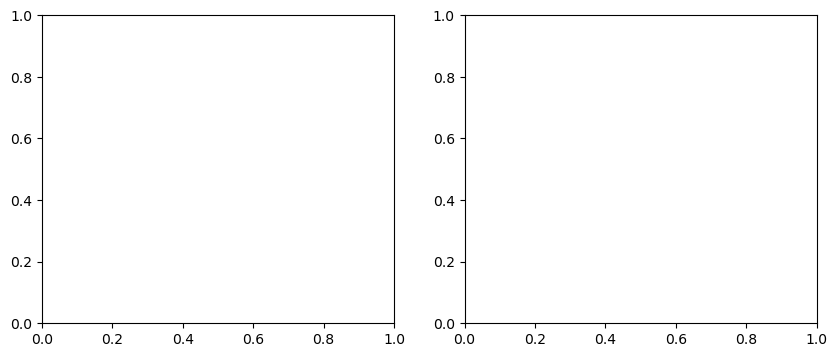

In [196]:
fig, (ax1,ax2) =plt.subplots(1,2, figsize=(10,4))
n = 15

ax1.imshow(np.abs(E), cmap='viridis',aspect='auto',norm='log')
ax1.set_xlabel('$\\varphi$ [rad]')
ax1.set_ylabel('$v_0$')
ax1.set_title('|$E/E(\\varphi=0)$|')
ax1.set_xticks(range(0, len(koti), n), np.around(koti[::n],3), rotation=90,fontsize=8)
ax1.set_yticks(range(0, len(v0_list), n), np.around(v0_list[::n],3), fontsize=8)

ax2.imshow(np.abs(l), cmap='viridis',aspect='auto',norm='log')
ax2.set_xticks(range(0, len(koti), n), np.around(koti[::n],3), rotation=90,fontsize=8)
ax2.set_yticks(range(0, len(v0_list), n), np.around(v0_list[::n],3), fontsize=8)
ax2.set_xlabel('$\\varphi$ [rad]')
ax2.set_ylabel('$v_0$')
ax2.set_title('|$l_z/l_z(\\varphi=0)$|')

plt.colorbar()
#plt.title(f'max dt={dt_max}')
#plt.savefig(f'./slike/2d_plot.pdf')

Text(0.5, 1.0, '|$l_z/l_z(\\varphi=0)$|')

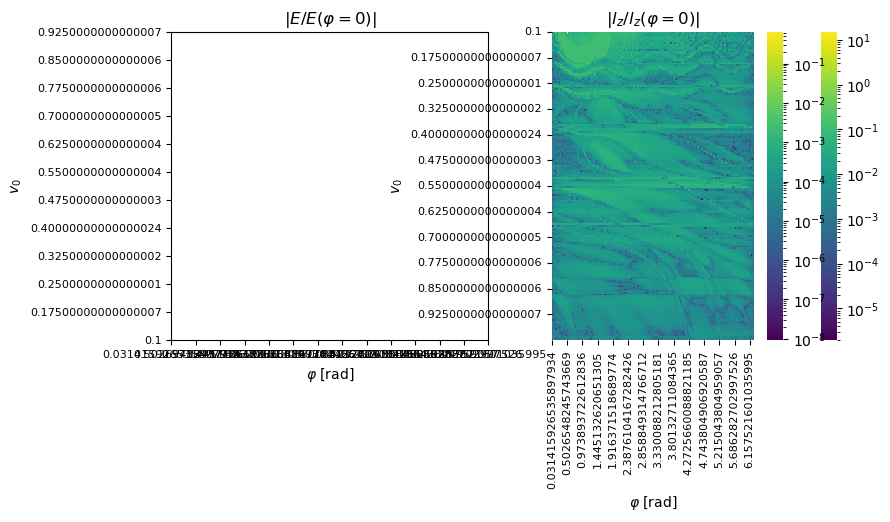

In [153]:
fig, (ax1,ax2) =plt.subplots(1,2, figsize=(9,4))

sns.heatmap(np.abs(E), xticklabels=koti, yticklabels=v0_list, cmap='viridis',norm='log')
n = 15
ax1.set_xticks(range(0, len(koti), n), koti[::n],  fontsize=8)
ax1.set_yticks(range(0, len(v0_list), n), v0_list[::n], fontsize=8)
ax1.set_xlabel('$\\varphi$ [rad]')
ax1.set_ylabel('$v_0$')
ax1.set_title('|$E/E(\\varphi=0)$|')

sns.heatmap(np.abs(l), xticklabels=koti, yticklabels=v0_list, cmap='viridis',norm='log')
n = 15
ax2.set_xticks(range(0, len(koti), n), koti[::n],  fontsize=8)
ax2.set_yticks(range(0, len(v0_list), n), v0_list[::n], fontsize=8)
ax2.set_xlabel('$\\varphi$ [rad]')
ax2.set_ylabel('$v_0$')
ax2.set_title('|$l_z/l_z(\\varphi=0)$|')
#plt.title(f'max dt={dt_max}')
#plt.savefig(f'./slike/dt_{dt_max}.pdf')